# 07 — Cross-Game Results and Robustness

Consolidates every result and tests whether the conclusions survive changes to
the arbitrary parts of the setup.

Run `python run_pipeline.py` first to populate `outputs/`.

In [1]:
import sys, warnings
from pathlib import Path

# Allow `from src import ...` when the notebook is run from notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
print("project root:", ROOT)

project root: D:\bhanu_fyp\player-churn-ml


In [2]:
from IPython.display import Image
from src import config

results = pd.read_csv(config.TABLE_DIR / "all_model_results.csv")
cohorts = pd.read_csv(config.TABLE_DIR / "cohort_summary.csv")
cohorts

,game,op_days,cp_days,players,churners,churn_rate,median_events_op
0,game1,5,10,25121,23261,0.925958,2.0
1,game2,5,10,79410,59960,0.755069,31.0
2,game3,5,10,24128,14477,0.600008,4.0


## Model performance across all three games

In [3]:
cols = ["game", "model", "roc_auc", "pr_auc_retained",
        "baseline_pr_retained", "lift_retained", "balanced_accuracy"]
results[cols].round(4).sort_values(["game", "roc_auc"], ascending=[True, False])

,game,model,roc_auc,pr_auc_retained,baseline_pr_retained,lift_retained,balanced_accuracy
3,game1,lstm,0.7834,0.3538,0.0740,4.7795,0.5622
0,game1,logistic_regression,0.7736,0.3372,0.0740,4.5552,0.5519
2,game1,xgboost,0.7418,0.3008,0.0740,4.0633,0.5838
1,game1,random_forest,0.7280,0.2946,0.0740,3.9798,0.5712
4,game2,logistic_regression,0.7585,0.5762,0.2449,2.3523,0.6216
6,game2,xgboost,0.7581,0.5788,0.2449,2.3630,0.6429
5,game2,random_forest,0.7574,0.5770,0.2449,2.3558,0.6327
7,game2,lstm,0.7441,0.5679,0.2449,2.3184,0.6296
8,game3,logistic_regression,0.8056,0.7689,0.3999,1.9227,0.7262
11,game3,lstm,0.8053,0.7743,0.3999,1.9361,0.7291


model,logistic_regression,lstm,random_forest,xgboost
game,,,,
game1,0.7736,0.7834,0.7280,0.7418
game2,0.7585,0.7441,0.7574,0.7581
game3,0.8056,0.8053,0.8034,0.8033


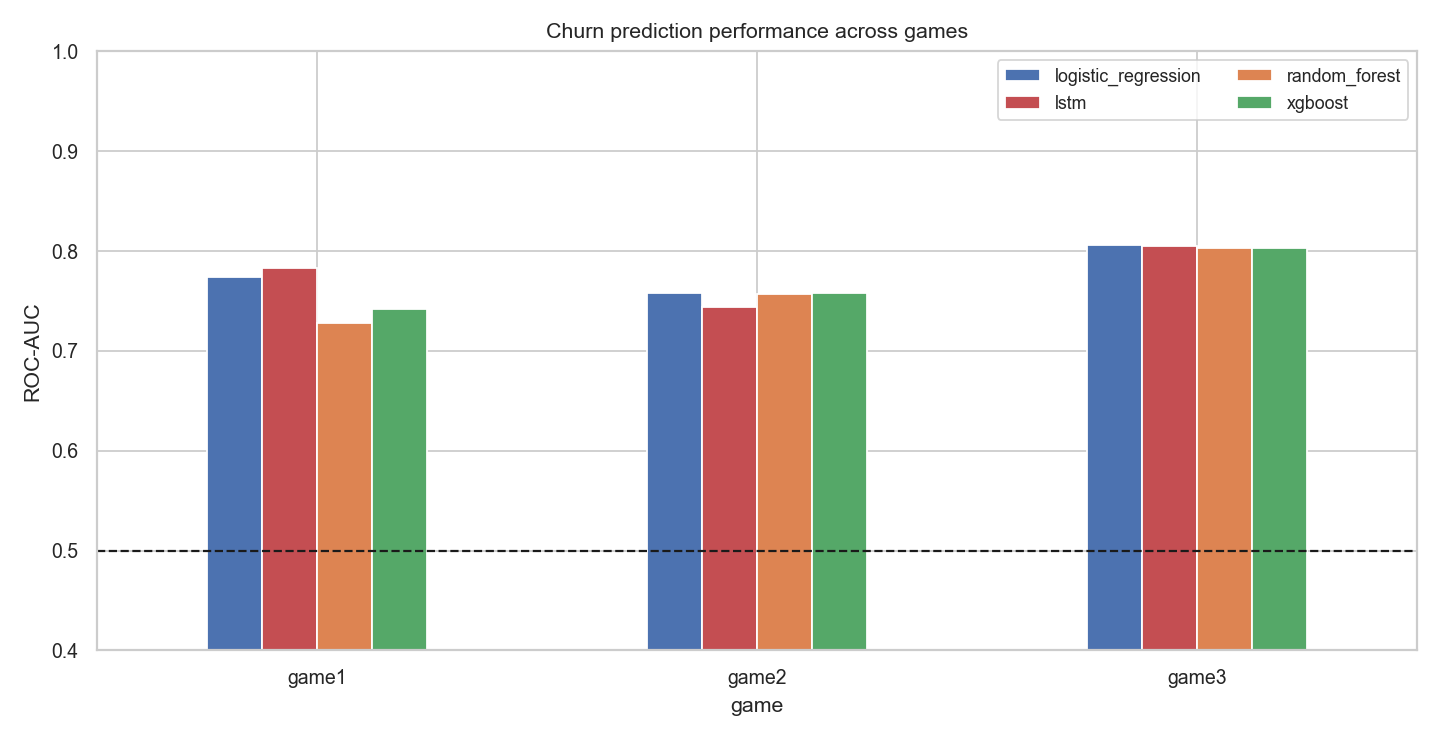

In [4]:
pivot = results.pivot_table(index="game", columns="model", values="roc_auc")
display(pivot.round(4))

Image(str(config.FIGURE_DIR / "cross_game_summary.png"))

### Which model wins where?

The source paper found no single dominant algorithm — gradient boosting led on
two games, LSTM on another. Reproducing that pattern (rather than finding one
universal winner) is itself a meaningful result: **the right churn model is
game-specific**, so a studio cannot simply lift an architecture from a paper.

In [5]:
winners = results.loc[results.groupby("game")["roc_auc"].idxmax(),
                      ["game", "model", "roc_auc"]]
winners.round(4)

,game,model,roc_auc
3,game1,lstm,0.7834
4,game2,logistic_regression,0.7585
8,game3,logistic_regression,0.8056


## Robustness — does the OP/CP choice drive the conclusions?

The 5/10-day windows are a convention, not a law. If the results only hold at
one setting, they are an artefact. Each game is re-labelled and re-fitted across
a grid of windows.

In [6]:
frames = []
for game in config.GAMES:
    path = config.TABLE_DIR / f"{game}_window_sensitivity.csv"
    if path.exists():
        frames.append(pd.read_csv(path))

sensitivity = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
sensitivity.round(4)

,game,op_days,cp_days,players,churn_rate,roc_auc,pr_auc_retained
0,game1,3,7,25469,0.9110,0.7508,0.3555
1,game1,5,10,25121,0.9260,0.7418,0.3008
2,game1,7,14,24715,0.9325,0.7559,0.3200
3,game1,5,30,24525,0.8997,0.7259,0.3465
4,game2,3,7,79416,0.7107,0.7417,0.5907
5,game2,5,10,79410,0.7551,0.7581,0.5788
6,game2,7,14,79397,0.7834,0.7566,0.5542
7,game2,5,30,79349,0.7022,0.7530,0.6248
8,game3,3,7,25396,0.5782,0.7850,0.7513
9,game3,5,10,24128,0.6000,0.8033,0.7750


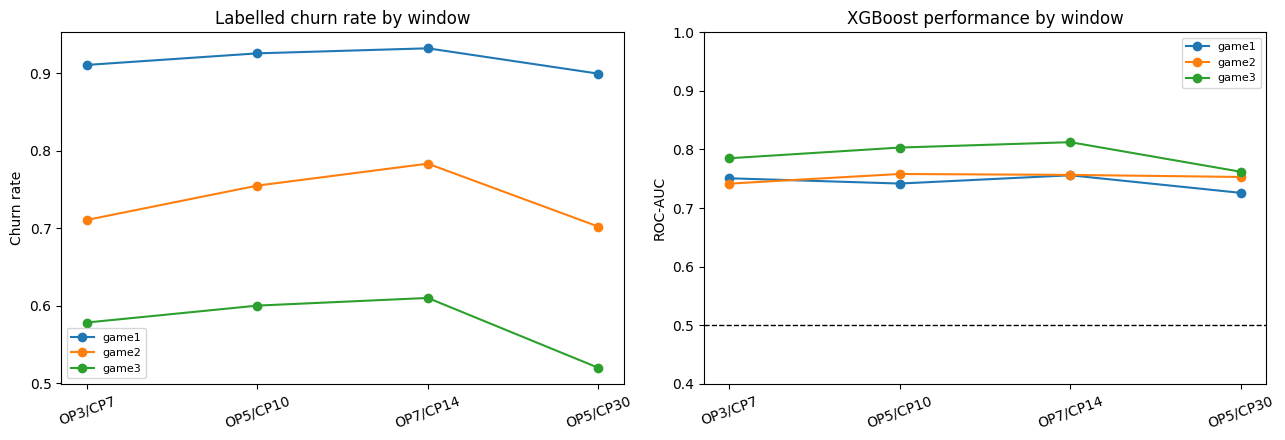

In [7]:
if not sensitivity.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for game, grp in sensitivity.groupby("game"):
        labels = [f"OP{r.op_days}/CP{r.cp_days}" for r in grp.itertuples()]
        axes[0].plot(labels, grp["churn_rate"], marker="o", label=game)
        axes[1].plot(labels, grp["roc_auc"], marker="o", label=game)

    axes[0].set(ylabel="Churn rate", title="Labelled churn rate by window")
    axes[1].set(ylabel="ROC-AUC", title="XGBoost performance by window", ylim=(0.4, 1.0))
    axes[1].axhline(0.5, ls="--", c="k", lw=1)
    for ax in axes:
        ax.legend(fontsize=8)
        ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    plt.show()

The churn *rate* moves a lot with the window — a longer CP always labels more
players as churners. What matters is whether **ROC-AUC stays stable**: if it
does, the model is detecting a real behavioural signal rather than an artefact
of where the boundary was drawn.

## Consolidated SHAP drivers

In [8]:
frames = []
for path in sorted(config.TABLE_DIR.glob("*_shap_importance.csv")):
    df = pd.read_csv(path)
    df["source"] = path.stem.replace("_shap_importance", "")
    frames.append(df.head(10))

if frames:
    shap_all = pd.concat(frames, ignore_index=True)
    display(shap_all.pivot_table(index="feature", columns="source",
                                 values="mean_abs_shap").round(4))

source,game1_logistic_regression,game1_xgboost,game2_logistic_regression,game3_logistic_regression
feature,,,,
active_duration_hours,NaN,0.3764,0.2216,0.0693
attempt_count,NaN,NaN,0.5338,NaN
complete_ratio,NaN,NaN,0.3529,NaN
consecutive_play_ratio,NaN,NaN,NaN,0.1899
day0_plays,NaN,NaN,0.2822,0.0710
day4_plays,NaN,NaN,NaN,0.1324
fail_event_count,NaN,NaN,0.2336,NaN
fail_ratio,NaN,NaN,0.4181,NaN
first_vs_last_day_ratio,0.1116,NaN,NaN,NaN


## Consolidated fairness findings

In [9]:
frames = []
for path in sorted(config.TABLE_DIR.glob("*_fairness_summary.csv")):
    df = pd.read_csv(path)
    df["game"] = path.stem.replace("_fairness_summary", "")
    frames.append(df)

if frames:
    fair_all = pd.concat(frames, ignore_index=True)
    display(fair_all.sort_values("auc_gap", ascending=False).round(4))

,attribute,groups,auc_gap,worst_group,worst_auc,best_group,best_auc,fnr_gap,fpr_gap,selection_rate_gap,game
0,engagement_tier,3,0.2500,light,0.5206,heavy,0.7706,0.0120,0.1550,0.0340,game1
7,engagement_tier,3,0.2419,light,0.5750,heavy,0.8169,0.2452,0.6982,0.5643,game3
8,skill_tier,3,0.1802,low,0.6482,mid,0.8284,0.1218,0.4524,0.3508,game3
2,skill_tier,3,0.1162,high,0.6652,low,0.7814,0.0919,0.4725,0.2399,game2
3,spend_tier,3,0.1069,low_spender,0.6747,non_spender,0.7816,0.0738,0.3429,0.1610,game2
4,engagement_tier,3,0.0974,medium,0.6607,heavy,0.7580,0.0902,0.4180,0.2235,game2
5,device_family,4,0.0572,iPod,0.7223,iPhone,0.7795,0.0047,0.0975,0.0277,game2
1,skill_tier,3,0.0541,mid,0.7360,high,0.7901,0.0060,0.1252,0.0209,game1
6,platform,2,0.0060,Android,0.7553,iOS,0.7612,0.0034,0.0270,0.0127,game2


## Limitations to state in the report

1. **Proxy labels.** Churn is inferred from inactivity, not a confirmed studio
   decision. A player who returns on day CP+1 is labelled a churner.
2. **No protected attributes.** The demographic fairness question in the original
   proposal cannot be answered with this data; behavioural and platform segments
   are substitutes and are reported as such.
3. **Cold start.** Performance is weakest for low-activity players — precisely
   the group with the most to gain from intervention.
4. **Correlation, not causation.** SHAP explains *the model*, not the game. It
   shows which behaviours the model uses to predict churn, which is not proof
   that changing those behaviours changes retention.
5. **Era and genre.** The logs are from 2014–2016 casual and web games; monetisation
   and retention design have moved on considerably.
6. **No intervention data.** Nothing here measures whether a reward actually saves
   a player. That requires an A/B test, and is the natural next study.

## Future work — the simulation strand

The agent-based simulation from the original proposal (how changing game design
parameters shifts aggregate retention) is deliberately left as future work. It
needs a validated behavioural model of how players *respond* to design changes,
which cannot be identified from observational logs where no intervention was
applied. Proposing it as a well-scoped next phase is stronger than rushing a
version whose assumptions cannot be defended.